## Loading libraries and Project setup

In [17]:
from collections import Counter
from pathlib import Path
import os
import sys
from tqdm import tqdm
from PIL import Image

PROJECT_ROOT = Path(os.getcwd()).resolve().parents[3]


if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Loading the Dataset and Model Classes
from dataloaders.csi_imd import CSIIMDDataset
from models.trufor.trufor_model import TruForInference


image_modes = Counter()
manipulated_images_dir = PROJECT_ROOT/ "datasets"/ "csi-imd"/ "manipulated_images"

png_image_paths = sorted(manipulated_images_dir.glob("*.png"))

for image_path in tqdm(png_image_paths,desc="Checking PNG Modes",unit="image"):
    with Image.open(image_path) as image:
        image_modes[image.mode] += 1

print("Source PNG Image Modes:")
for mode, count in image_modes.items():
    print(f"{mode:<10}: {count:,}")

# Override any backend set by imported code
import matplotlib
matplotlib.use("module://matplotlib_inline.backend_inline",force=True)
import matplotlib.pyplot as plt

Checking PNG Modes: 100%|██████████| 1000/1000 [00:00<00:00, 6587.84image/s]

Source PNG Image Modes:
RGB       : 1,000


In [3]:
######  CSI-IMD Manipulated PNG to JPEG Quality Sweep  ######

from pathlib import Path

from PIL import Image
from tqdm import tqdm


# ============================================================
# Configuration
# ============================================================

# Provide the actual CSI-IMD manipulated image directory here
manipulated_images_dir = PROJECT_ROOT/ "datasets"/ "csi-imd"/ "manipulated_images"

# CSI-IMD Dataset Root
dataset_root = manipulated_images_dir.parent

# JPEG Quality Levels
JPEG_QUALITIES = [100, 95, 90, 85, 75]


# ============================================================
# Load Original Manipulated PNG Images
# ============================================================

png_image_paths = sorted(manipulated_images_dir.glob("*.png"))

if not png_image_paths:
    raise FileNotFoundError(
        f"No PNG images found in: {manipulated_images_dir}"
    )

print("=" * 70)
print("CSI-IMD JPEG CONVERSION CONFIGURATION")
print("=" * 70)

print(f"Source Directory : {manipulated_images_dir}")
print(f"PNG Images       : {len(png_image_paths):,}")
print(f"JPEG Qualities   : {JPEG_QUALITIES}")


# ============================================================
# JPEG Conversion
# ============================================================

for quality in JPEG_QUALITIES:

    # Output Directory
    output_dir = dataset_root / f"manipulated_jpeg_q{quality}"
    output_dir.mkdir(parents=True, exist_ok=True)

    print("\n" + "=" * 70)
    print(f"CONVERTING MANIPULATED PNG IMAGES TO JPEG Q{quality}")
    print("=" * 70)

    print(f"Output Directory : {output_dir}")

    for image_path in tqdm(
        png_image_paths,
        desc=f"JPEG Q{quality}",
        unit="image",
    ):

        # Output JPEG Path
        output_path = output_dir / f"{image_path.stem}.jpg"

        # Load Original Manipulated PNG
        with Image.open(image_path) as image:

            # JPEG Does Not Support Alpha Channels
            if image.mode != "RGB":
                image = image.convert("RGB")

            # Save as JPEG
            image.save(
                output_path,
                format="JPEG",
                quality=quality,
                subsampling=0,
                optimize=False,
                progressive=False,
            )

    print(f"JPEG Q{quality} conversion complete.")
    print(f"Saved Images : {len(png_image_paths):,}")


# ============================================================
# Conversion Summary
# ============================================================

print("\n" + "=" * 70)
print("CSI-IMD JPEG QUALITY SWEEP CONVERSION COMPLETE")
print("=" * 70)

print(f"Source PNG Images : {len(png_image_paths):,}")

for quality in JPEG_QUALITIES:

    output_dir = dataset_root / f"manipulated_jpeg_q{quality}"
    jpeg_count = len(list(output_dir.glob("*.jpg")))

    print(
        f"JPEG Q{quality:<3} : "
        f"{jpeg_count:,} images | "
        f"{output_dir}"
    )

CSI-IMD JPEG CONVERSION CONFIGURATION
Source Directory : /Users/arjunmallick/1. IISc/5. M.Tech Thesis Project/2. SOTA Experiments/imdl-testbed/datasets/csi-imd/manipulated_images
PNG Images       : 1,000
JPEG Qualities   : [100, 95, 90, 85, 75]

CONVERTING MANIPULATED PNG IMAGES TO JPEG Q100
Output Directory : /Users/arjunmallick/1. IISc/5. M.Tech Thesis Project/2. SOTA Experiments/imdl-testbed/datasets/csi-imd/manipulated_jpeg_q100


JPEG Q100: 100%|██████████| 1000/1000 [00:05<00:00, 189.93image/s]


JPEG Q100 conversion complete.
Saved Images : 1,000

CONVERTING MANIPULATED PNG IMAGES TO JPEG Q95
Output Directory : /Users/arjunmallick/1. IISc/5. M.Tech Thesis Project/2. SOTA Experiments/imdl-testbed/datasets/csi-imd/manipulated_jpeg_q95


JPEG Q95: 100%|██████████| 1000/1000 [00:03<00:00, 252.84image/s]


JPEG Q95 conversion complete.
Saved Images : 1,000

CONVERTING MANIPULATED PNG IMAGES TO JPEG Q90
Output Directory : /Users/arjunmallick/1. IISc/5. M.Tech Thesis Project/2. SOTA Experiments/imdl-testbed/datasets/csi-imd/manipulated_jpeg_q90


...

JPEG Q90 conversion complete.
Saved Images : 1,000

CONVERTING MANIPULATED PNG IMAGES TO JPEG Q85
Output Directory : /Users/arjunmallick/1. IISc/5. M.Tech Thesis Project/2. SOTA Experiments/imdl-testbed/datasets/csi-imd/manipulated_jpeg_q85


JPEG Q85: 100%|██████████| 1000/1000 [00:03<00:00, 251.62image/s]


JPEG Q85 conversion complete.
Saved Images : 1,000

CONVERTING MANIPULATED PNG IMAGES TO JPEG Q75
Output Directory : /Users/arjunmallick/1. IISc/5. M.Tech Thesis Project/2. SOTA Experiments/imdl-testbed/datasets/csi-imd/manipulated_jpeg_q75


JPEG Q75: 100%|██████████| 1000/1000 [00:04<00:00, 239.27image/s]

JPEG Q75 conversion complete.
Saved Images : 1,000

CSI-IMD JPEG QUALITY SWEEP CONVERSION COMPLETE
Source PNG Images : 1,000
JPEG Q100 : 1,000 images | /Users/arjunmallick/1. IISc/5. M.Tech Thesis Project/2. SOTA Experiments/imdl-testbed/datasets/csi-imd/manipulated_jpeg_q100
JPEG Q95  : 1,000 images | /Users/arjunmallick/1. IISc/5. M.Tech Thesis Project/2. SOTA Experiments/imdl-testbed/datasets/csi-imd/manipulated_jpeg_q95
JPEG Q90  : 1,000 images | /Users/arjunmallick/1. IISc/5. M.Tech Thesis Project/2. SOTA Experiments/imdl-testbed/datasets/csi-imd/manipulated_jpeg_q90
JPEG Q85  : 1,000 images | /Users/arjunmallick/1. IISc/5. M.Tech Thesis Project/2. SOTA Experiments/imdl-testbed/datasets/csi-imd/manipulated_jpeg_q85
JPEG Q75  : 1,000 images | /Users/arjunmallick/1. IISc/5. M.Tech Thesis Project/2. SOTA Experiments/imdl-testbed/datasets/csi-imd/manipulated_jpeg_q75


## Inference Pipeline

In [5]:
######  JPEG Compression TruFor Inference Experiment  ######

from datetime import datetime
from pathlib import Path
import sys
import os
import csv

from tqdm import tqdm

import numpy as np
import pandas as pd
import torch
from torchvision import transforms
from torch.utils.data import DataLoader

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
)


# ============================================================
# Project Configuration
# ============================================================

PROJECT_ROOT = Path(os.getcwd()).resolve().parents[3]

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))


# ============================================================
# Load Dataset and Model Classes
# ============================================================

from dataloaders.csi_imd import CSIIMDDataset
from models.trufor.trufor_model import TruForInference


DATASET_NAME = "CSI-IMD"


# ============================================================
# TruFor Image Preprocessing
# ============================================================

class TruForTransform:
    """
    TruFor image preprocessing.

    Pipeline:
        PIL RGB Image
            -> NumPy HWC
            -> CHW
            -> torch.float32
            -> scale by 255.0
    """

    def __call__(self, image):

        image = np.array(image)

        image = torch.tensor(
            image.transpose(2, 0, 1),
            dtype=torch.float32,
        )

        image = image / 255.0

        return image


# ============================================================
# Dataset / Model Configuration
# ============================================================

dataset_root = PROJECT_ROOT / "datasets" / "csi-imd"

checkpoint_path = (
    PROJECT_ROOT
    / "models"
    / "trufor"
    / "TruFor_train_test"
    / "pretrained_models"
    / "trufor.pth.tar"
)

image_transform = TruForTransform()
mask_transform = transforms.ToTensor()


# ============================================================
# JPEG Compression Variants
# ============================================================

# JPEG_VARIANTS = {
#     "Q100": "manipulated_jpeg_q100",
#     "Q95": "manipulated_jpeg_q95",
#     "Q90": "manipulated_jpeg_q90",
#     "Q85": "manipulated_jpeg_q85",
#     "Q75": "manipulated_jpeg_q75",
# }

JPEG_VARIANTS = {
    "Q95": "manipulated_jpeg_q95",
    "Q90": "manipulated_jpeg_q90",
    "Q85": "manipulated_jpeg_q85",
    "Q75": "manipulated_jpeg_q75",
}


# ============================================================
# Output Directory
# ============================================================

output_dir = Path(os.getcwd()) / "outputs_jpeg"
output_dir.mkdir(parents=True, exist_ok=True)


# ============================================================
# CSV Schema
# ============================================================

CSV_COLUMNS = [
    "run_timestamp",
    "compression_level",
    "image_id",
    "file_name",
    "label",
    "image_path",
    "image_height",
    "image_width",
    "score",
    "inference_status",
    "error_type",
    "error_message",
    "npz_path"
]


# ============================================================
# Classification Threshold
# ============================================================

THRESHOLD = 0.5


print("=" * 70)
print("CSI-IMD JPEG COMPRESSION EXPERIMENT")
print("=" * 70)

print(f"Dataset Root       : {dataset_root}")
print(f"Output Directory   : {output_dir}")
print(f"Compression Levels : {list(JPEG_VARIANTS.keys())}")
print(f"Threshold          : {THRESHOLD}")

CSI-IMD JPEG COMPRESSION EXPERIMENT
Dataset Root       : /Users/arjunmallick/1. IISc/5. M.Tech Thesis Project/2. SOTA Experiments/imdl-testbed/datasets/csi-imd
Output Directory   : /Users/arjunmallick/1. IISc/5. M.Tech Thesis Project/2. SOTA Experiments/imdl-testbed/experiments/detection/csi-imd/trufor/outputs_jpeg
Compression Levels : ['Q95', 'Q90', 'Q85', 'Q75']
Threshold          : 0.5


In [6]:
######  Load TruFor Model  ######

trufor = TruForInference(checkpoint_path=checkpoint_path,experiment="trufor_ph3",
                         device=None,save_np=True)

print("=" * 70)
print("TRUFOR MODEL LOADED")
print("=" * 70)

print(f"Checkpoint : {checkpoint_path}")

Using device : mps
Loaded checkpoint (epoch=81)
Model loaded on : mps:0
TRUFOR MODEL LOADED
Checkpoint : /Users/arjunmallick/1. IISc/5. M.Tech Thesis Project/2. SOTA Experiments/imdl-testbed/models/trufor/TruFor_train_test/pretrained_models/trufor.pth.tar


In [25]:
######  Run TruFor Inference for Each JPEG Compression Level  ######

experiment_csv_paths = {}


for compression_level, manipulation_dir in JPEG_VARIANTS.items():

    print("\n" + "=" * 70)
    print(f"RUNNING JPEG {compression_level} EXPERIMENT")
    print("=" * 70)

    print(f"Manipulated Directory : {manipulation_dir}")


    # ============================================================
    # Create Dataset
    # ============================================================

    dataset = CSIIMDDataset(
        root=dataset_root,
        split="train",
        task="detection",
        manipulation_dir=manipulation_dir,
        max_real=None,
        max_fake=None,
        seed=42,
        transform=image_transform,
        target_transform=mask_transform,
    )

    print(f"\n{DATASET_NAME} {compression_level} DATASET LOADED...")
    print(dataset)


    # ============================================================
    # Create DataLoader
    # ============================================================

    dataloader = DataLoader(
        dataset,
        batch_size=1,
        shuffle=False,
        num_workers=0,
    )

    print(f"\n{DATASET_NAME} {compression_level} DATALOADER CREATED...")
    print("-" * 70)

    print(f"Dataset samples    : {len(dataset):,}")
    print(f"DataLoader batches : {len(dataloader):,}")
    print("Batch size         : 1")
    print("Shuffle            : False")
    print("Num workers        : 0")


    # ============================================================
    # Output CSV
    # ============================================================

    run_timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
    output_csv = (output_dir/ f"detection_scores_{compression_level.lower()}_{run_timestamp}.csv")
    experiment_csv_paths[compression_level] = output_csv    
    
    
    # ============================================================
    # Output NPZ Directories
    # ============================================================

    npz_root = output_dir / f"npz_{compression_level.lower()}"

    real_npz_dir = npz_root / "real"
    fake_npz_dir = npz_root / "manipulated"

    real_npz_dir.mkdir(parents=True, exist_ok=True)
    fake_npz_dir.mkdir(parents=True, exist_ok=True)



    # ============================================================
    # Run Inference
    # ============================================================

    successful_inferences = 0
    failed_inferences = 0

    with open(output_csv,mode="w",newline="",encoding="utf-8") as csv_file:

        writer = csv.DictWriter(csv_file,fieldnames=CSV_COLUMNS,)
        writer.writeheader()

        for batch in tqdm(dataloader,desc=f"{compression_level} TruFor Inference",unit="image"):

            # ----------------------------------------------------
            # Sample Metadata
            # ----------------------------------------------------

            image_id = batch["image_id"][0]
            file_name = batch["file_name"][0]
            image_path = batch["image_path"][0]

            label = batch["label"].item()
            image = batch["image"]


            # ----------------------------------------------------
            # Input Spatial Size
            # ----------------------------------------------------

            image_height = image.shape[2]
            image_width = image.shape[3]


            # ----------------------------------------------------
            # Inference
            # ----------------------------------------------------

            try:

                output = trufor.predict(image)

                output = trufor.predict(image)

                score = float(
                    output.get(
                        "score",
                        float("nan"),
                    )
                )

                anomaly_map = output.get("map")
                confidence_map = output.get("conf")
                noiseprint = output.get("np++")


                # ----------------------------------------------------
                # Save NPZ
                # ----------------------------------------------------

                if label == 0:
                    npz_path = real_npz_dir / f"{image_id}.npz"
                else:
                    npz_path = fake_npz_dir / f"{image_id}.npz"

                np.savez_compressed(
                    npz_path,
                    map=np.asarray(anomaly_map),
                    conf=np.asarray(confidence_map),
                    **{"np++": np.asarray(noiseprint)},
                )


                writer.writerow(
                    {
                        "run_timestamp": run_timestamp,
                        "compression_level": compression_level,
                        "image_id": image_id,
                        "file_name": file_name,
                        "label": label,
                        "image_path": image_path,
                        "image_height": image_height,
                        "image_width": image_width,
                        "score": score,
                        "npz_path": str(npz_path),
                        "inference_status": "success",
                        "error_type": "",
                        "error_message": "",
                    }
                )

                successful_inferences += 1


            except Exception as exc:

                writer.writerow(
                    {
                        "run_timestamp": run_timestamp,
                        "compression_level": compression_level,
                        "image_id": image_id,
                        "file_name": file_name,
                        "label": label,
                        "image_path": image_path,
                        "image_height": image_height,
                        "image_width": image_width,
                        "score": "",
                        "npz_path": "",
                        "inference_status": "failed",
                        "error_type": type(exc).__name__,
                        "error_message": str(exc),
                    }
                )

                failed_inferences += 1


            # ----------------------------------------------------
            # Write Results Incrementally
            # ----------------------------------------------------

            csv_file.flush()


    # ============================================================
    # Inference Summary
    # ============================================================

    print("\n" + "-" * 70)
    print(f"{compression_level} TRUFOR INFERENCE COMPLETE")
    print("-" * 70)

    print(f"Run Timestamp         : {run_timestamp}")
    print(f"Total Samples         : {len(dataset):,}")
    print(f"Successful Inferences : {successful_inferences:,}")
    print(f"Failed Inferences     : {failed_inferences:,}")
    print(f"Output CSV            : {output_csv}")
    print(f"Output NPZ Folder      : {npz_root}")


RUNNING JPEG Q95 EXPERIMENT
Manipulated Directory : manipulated_jpeg_q95


Indexing manipulated images: 100%|██████████| 1000/1000 [00:00<00:00, 1021506.09files/s]



CSI-IMD Q95 DATASET LOADED...
CSIIMDDataset(
  split=train,
  task=detection,
  real_images=200,
  fake_images=1000,
  total_images=1200
)

CSI-IMD Q95 DATALOADER CREATED...
----------------------------------------------------------------------
Dataset samples    : 1,200
DataLoader batches : 1,200
Batch size         : 1
Shuffle            : False
Num workers        : 0


Q95 TruFor Inference: 100%|██████████| 1200/1200 [12:59<00:00,  1.54image/s]



----------------------------------------------------------------------
Q95 TRUFOR INFERENCE COMPLETE
----------------------------------------------------------------------
Run Timestamp         : 20260714_190206
Total Samples         : 1,200
Successful Inferences : 1,200
Failed Inferences     : 0
Output CSV            : /Users/arjunmallick/1. IISc/5. M.Tech Thesis Project/2. SOTA Experiments/imdl-testbed/experiments/detection/csi-imd/trufor/outputs_jpeg/detection_scores_q95_20260714_190206.csv
Output NPZ Folder      : /Users/arjunmallick/1. IISc/5. M.Tech Thesis Project/2. SOTA Experiments/imdl-testbed/experiments/detection/csi-imd/trufor/outputs_jpeg/npz_q95

RUNNING JPEG Q90 EXPERIMENT
Manipulated Directory : manipulated_jpeg_q90


...


----------------------------------------------------------------------
Q85 TRUFOR INFERENCE COMPLETE
----------------------------------------------------------------------
Run Timestamp         : 20260714_192906
Total Samples         : 1,200
Successful Inferences : 1,200
Failed Inferences     : 0
Output CSV            : /Users/arjunmallick/1. IISc/5. M.Tech Thesis Project/2. SOTA Experiments/imdl-testbed/experiments/detection/csi-imd/trufor/outputs_jpeg/detection_scores_q85_20260714_192906.csv
Output NPZ Folder      : /Users/arjunmallick/1. IISc/5. M.Tech Thesis Project/2. SOTA Experiments/imdl-testbed/experiments/detection/csi-imd/trufor/outputs_jpeg/npz_q85

RUNNING JPEG Q75 EXPERIMENT
Manipulated Directory : manipulated_jpeg_q75


Indexing manipulated images: 100%|██████████| 1000/1000 [00:00<00:00, 1032062.99files/s]



CSI-IMD Q75 DATASET LOADED...
CSIIMDDataset(
  split=train,
  task=detection,
  real_images=200,
  fake_images=1000,
  total_images=1200
)

CSI-IMD Q75 DATALOADER CREATED...
----------------------------------------------------------------------
Dataset samples    : 1,200
DataLoader batches : 1,200
Batch size         : 1
Shuffle            : False
Num workers        : 0


Q75 TruFor Inference: 100%|██████████| 1200/1200 [14:07<00:00,  1.42image/s]


----------------------------------------------------------------------
Q75 TRUFOR INFERENCE COMPLETE
----------------------------------------------------------------------
Run Timestamp         : 20260714_194332
Total Samples         : 1,200
Successful Inferences : 1,200
Failed Inferences     : 0
Output CSV            : /Users/arjunmallick/1. IISc/5. M.Tech Thesis Project/2. SOTA Experiments/imdl-testbed/experiments/detection/csi-imd/trufor/outputs_jpeg/detection_scores_q75_20260714_194332.csv
Output NPZ Folder      : /Users/arjunmallick/1. IISc/5. M.Tech Thesis Project/2. SOTA Experiments/imdl-testbed/experiments/detection/csi-imd/trufor/outputs_jpeg/npz_q75


In [12]:
######  JPEG Compression Detection Performance Analysis  ######

metrics_results = []


for compression_level, csv_path in experiment_csv_paths.items():

    # ============================================================
    # Load Inference Results
    # ============================================================

    results_df = pd.read_csv(csv_path)


    # ============================================================
    # Keep Successful Inferences
    # ============================================================

    successful_df = results_df[
        results_df["inference_status"] == "success"
    ].copy()

    failed_df = results_df[
        results_df["inference_status"] == "failed"
    ].copy()


    print("\n" + "=" * 70)
    print(f"{compression_level} INFERENCE RESULTS")
    print("=" * 70)

    print(f"CSV File              : {csv_path.name}")
    print(f"Total Samples         : {len(results_df):,}")
    print(f"Successful Inferences : {len(successful_df):,}")
    print(f"Failed Inferences     : {len(failed_df):,}")


    # ============================================================
    # Ground Truth and Predictions
    # ============================================================

    y_true = successful_df["label"].astype(int)

    y_score = successful_df["score"].astype(float)

    y_pred = (
        y_score >= THRESHOLD
    ).astype(int)


    # ============================================================
    # Classification Metrics
    # ============================================================

    accuracy = accuracy_score(
        y_true,
        y_pred,
    )

    precision = precision_score(
        y_true,
        y_pred,
        zero_division=0,
    )

    recall = recall_score(
        y_true,
        y_pred,
        zero_division=0,
    )

    f1 = f1_score(
        y_true,
        y_pred,
        zero_division=0,
    )

    auc = roc_auc_score(
        y_true,
        y_score,
    )


    # ============================================================
    # Store Metrics
    # ============================================================

    metrics_results.append(
        {
            "Compression Level": compression_level,
            "Accuracy": accuracy,
            "Precision": precision,
            "Recall": recall,
            "F1": f1,
            "AUC": auc,
        }
    )


Q100 INFERENCE RESULTS
CSV File              : detection_scores_q100_20260714_161614.csv
Total Samples         : 1,200
Successful Inferences : 1,200
Failed Inferences     : 0

Q95 INFERENCE RESULTS
CSV File              : detection_scores_q95_20260714_162218.csv
Total Samples         : 1,200
Successful Inferences : 1,200
Failed Inferences     : 0

Q90 INFERENCE RESULTS
CSV File              : detection_scores_q90_20260714_162858.csv
Total Samples         : 1,200
Successful Inferences : 1,200
Failed Inferences     : 0

Q85 INFERENCE RESULTS
CSV File              : detection_scores_q85_20260714_163549.csv
Total Samples         : 1,200
Successful Inferences : 1,200
Failed Inferences     : 0

Q75 INFERENCE RESULTS
CSV File              : detection_scores_q75_20260714_164250.csv
Total Samples         : 1,200
Successful Inferences : 1,200
Failed Inferences     : 0


In [13]:
######  JPEG Compression Performance Comparison Table  ######

metrics_comparison_df = pd.DataFrame(metrics_results)


# ============================================================
# Preserve JPEG Quality Ordering
# ============================================================

compression_order = [
    "Q100",
    "Q95",
    "Q90",
    "Q85",
    "Q75",
]

metrics_comparison_df["Compression Level"] = pd.Categorical(
    metrics_comparison_df["Compression Level"],
    categories=compression_order,
    ordered=True,
)

metrics_comparison_df = (
    metrics_comparison_df
    .sort_values("Compression Level")
    .set_index("Compression Level")
)


# ============================================================
# Display Comparison Table
# ============================================================

print("=" * 70)
print("CSI-IMD TRUFOR JPEG COMPRESSION PERFORMANCE")
print("=" * 70)

display(
    metrics_comparison_df.style.format(
        {
            "Accuracy": "{:.4f}",
            "Precision": "{:.4f}",
            "Recall": "{:.4f}",
            "F1": "{:.4f}",
            "AUC": "{:.4f}",
        }
    )
)

CSI-IMD TRUFOR JPEG COMPRESSION PERFORMANCE


,Accuracy,Precision,Recall,F1,AUC
Compression Level,,,,,
Q100,0.8908,0.9759,0.8910,0.9315,0.9544
Q95,0.7583,0.9708,0.7320,0.8347,0.8472
Q90,0.6317,0.9635,0.5800,0.7241,0.7521
Q85,0.5992,0.9609,0.5410,0.6923,0.7558
Q75,0.3192,0.9031,0.2050,0.3341,0.6232


## Analysis of Pristine Images

In [6]:

from pathlib import Path
from collections import Counter
import os, sys
import numpy as np
import pandas as pd

from PIL import Image
from PIL.JpegImagePlugin import JpegImageFile

from tqdm import tqdm

import matplotlib.pyplot as plt

PROJECT_ROOT = Path(os.getcwd()).resolve().parents[3]


if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

DATASET_ROOT = PROJECT_ROOT/ "datasets"/ "csi-imd"
PRISTINE_DIR = DATASET_ROOT / "pristine_images_used_for_manipulation"

image_paths = sorted(PRISTINE_DIR.glob("*.jpg"))
print(f"Number of pristine JPEG images : {len(image_paths)}")

Number of pristine JPEG images : 200


### JPEG Level Estimation

In [7]:
STANDARD_LUMA_Q50 = np.array([
16,11,10,16,24,40,51,61,
12,12,14,19,26,58,60,55,
14,13,16,24,40,57,69,56,
14,17,22,29,51,87,80,62,
18,22,37,56,68,109,103,77,
24,35,55,64,81,104,113,92,
49,64,78,87,103,121,120,101,
72,92,95,98,112,100,103,99])

def estimate_quality(qtable):
    qtable = np.asarray(qtable)
    scale = np.median( qtable / STANDARD_LUMA_Q50)

    if scale <= 1:
        quality = 100 - 50 * scale
    else:
        quality = 5000 / (scale * 100)

    return int(round(max(1, min(100, quality))))


def get_sampling(image):
    try:
        layer = image.layer
        sampling = tuple((v[1], v[2]) for v in layer)
        return sampling

    except Exception:
        return None

In [12]:
records = []

for image_path in tqdm(image_paths):
    with Image.open(image_path) as img:
        if not isinstance(img, JpegImageFile):
            continue

        width, height = img.size
        filesize = image_path.stat().st_size
        qtables = img.quantization
        num_tables = len(qtables)
        luma_table = qtables[0]
        quality = estimate_quality(luma_table)
        sampling = get_sampling(img)

        records.append({
            "image_name": image_path.name,
            "width": width,
            "height": height,
            "pixels": width * height,
            "file_size_bytes": filesize,
            "num_qtables": num_tables,
            "estimated_quality": quality,
            "sampling": str(sampling),
            "luma_table": tuple(luma_table)})

jpeg_df = pd.DataFrame(records)
jpeg_df.head()

100%|██████████| 200/200 [00:00<00:00, 8681.70it/s]


,image_name,width,height,pixels,file_size_bytes,num_qtables,estimated_quality,sampling,luma_table
0,1.jpg,800,531,424800,80898,2,90,"((2, 2), (1, 1), (1, 1))","(3, 2, 2, 3, 5, 8, 10, 12, 2, 2, 3, 4, 5, 12, ..."
1,10.jpg,640,480,307200,52283,2,75,"((2, 2), (1, 1), (1, 1))","(8, 6, 5, 8, 12, 20, 26, 31, 6, 6, 7, 10, 13, ..."
2,100.jpg,640,480,307200,70258,2,75,"((2, 2), (1, 1), (1, 1))","(8, 6, 5, 8, 12, 20, 26, 31, 6, 6, 7, 10, 13, ..."
3,101.jpg,400,300,120000,25377,2,75,"((2, 2), (1, 1), (1, 1))","(8, 6, 5, 8, 12, 20, 26, 31, 6, 6, 7, 10, 13, ..."
4,102.jpg,400,300,120000,27646,2,75,"((2, 2), (1, 1), (1, 1))","(8, 6, 5, 8, 12, 20, 26, 31, 6, 6, 7, 10, 13, ..."


In [13]:
display( jpeg_df[["width","height","pixels"]].describe())
display(jpeg_df["file_size_bytes"].describe())

,width,height,pixels
count,200.000000,200.000000,200.000000
mean,566.060000,414.550000,241535.200000
std,111.954749,93.053491,84422.995992
min,360.000000,300.000000,120000.000000
25%,400.000000,300.000000,120000.000000
50%,640.000000,480.000000,307200.000000
75%,640.000000,480.000000,307200.000000
max,800.000000,800.000000,480000.000000


count       200.000000
mean      49715.665000
std       17562.560717
min       20447.000000
25%       32176.000000
50%       52247.500000
75%       61923.250000
max      125635.000000
Name: file_size_bytes, dtype: float64

estimated_quality
75    197
90      3
Name: count, dtype: int64

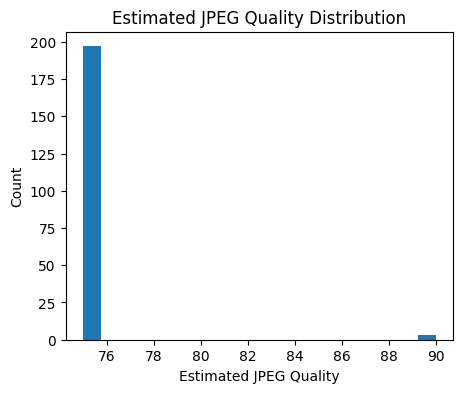

In [18]:
quality_counts = (jpeg_df["estimated_quality"].value_counts().sort_index())
display(quality_counts)

plt.figure(figsize=(5,4))
plt.hist(jpeg_df["estimated_quality"], bins=20)
plt.xlabel("Estimated JPEG Quality")
plt.ylabel("Count")
plt.title("Estimated JPEG Quality Distribution")
plt.show()

In [19]:
sampling_counts = (jpeg_df["sampling"].value_counts())
display(sampling_counts)

sampling
((2, 2), (1, 1), (1, 1))    200
Name: count, dtype: int64

In [20]:
table_counts = Counter(jpeg_df["luma_table"])
table_summary = pd.DataFrame({
"table": list(table_counts.keys()),
"count": list(table_counts.values())})

table_summary = table_summary.sort_values("count", ascending=False)
display(table_summary.head(10))

,table,count
1,"(8, 6, 5, 8, 12, 20, 26, 31, 6, 6, 7, 10, 13, ...",197
0,"(3, 2, 2, 3, 5, 8, 10, 12, 2, 2, 3, 4, 5, 12, ...",3


In [21]:
print("="*60)

print("CSI-IMD PRISTINE JPEG SUMMARY")

print("="*60)

print()

print(

"Images:",

len(jpeg_df)

)

print()

print(

"Dominant Estimated Quality"

)

print(

jpeg_df["estimated_quality"]

.mode()

.tolist()

)

print()

print(

"Dominant Chroma Sampling"

)

print(

jpeg_df["sampling"]

.mode()

.tolist()

)

print()

print(

"Most Common Quantization Table Frequency"

)

print(

table_summary.iloc[0]["count"]

)

print()

print(

"Unique Quantization Tables"

)

print(

len(table_summary)

)

print()

print(

"Median File Size (KB)"

)

print(

jpeg_df["file_size_bytes"].median()/1024

)

print()

print(

"Median Dimensions"

)

print(

jpeg_df["width"].median(),

"x",

jpeg_df["height"].median()

)

CSI-IMD PRISTINE JPEG SUMMARY

Images: 200

Dominant Estimated Quality
[75]

Dominant Chroma Sampling
['((2, 2), (1, 1), (1, 1))']

Most Common Quantization Table Frequency
197

Unique Quantization Tables
2

Median File Size (KB)
51.02294921875

Median Dimensions
640.0 x 480.0


## Noiseprint++ Visualization

In [7]:
# ============================================================
# Imports
# ============================================================

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image


# ============================================================
# JPEG Experiment Configuration
# ============================================================

# Change only these two paths for another JPEG quality

JPEG_Q90_CSV = (
    PROJECT_ROOT
    / "experiments"
    / "detection"
    / "csi-imd"
    / "trufor"
    / "outputs_jpeg"
    / "detection_scores_q90.csv"
)

JPEG_Q90_NPZ_DIR = (
    PROJECT_ROOT
    / "experiments"
    / "detection"
    / "csi-imd"
    / "trufor"
    / "outputs_jpeg"
    / "npz_q90"
)


# ============================================================
# Load JPEG-Q90 CSV
# ============================================================

jpeg_df = pd.read_csv(JPEG_Q90_CSV)

print(f"JPEG-Q90 Samples : {len(jpeg_df)}")

JPEG-Q90 Samples : 1200


In [8]:
# ============================================================
# Noiseprint Visualization
# ============================================================

def preprocess_noiseprint(noiseprint):
    noiseprint = noiseprint.astype(np.float32)
    noiseprint = noiseprint - noiseprint.mean()
    return noiseprint


# ============================================================
# Load TruFor Outputs
# ============================================================

def load_npz(npz_path):
    with np.load(npz_path) as npz:
        noiseprint = np.squeeze(npz["np++"]).astype(np.float32)
        anomaly = np.squeeze(npz["map"]).astype(np.float32)
        confidence = np.squeeze(npz["conf"]).astype(np.float32)

    return noiseprint, anomaly, confidence

# ============================================================
# JPEG NPZ Path
# ============================================================

def get_jpeg_npz_path(image_id,label):
    folder = ( "real" if label == 0 else "manipulated")
    return (JPEG_Q90_NPZ_DIR/ folder/ f"{image_id}.npz")


# ============================================================
# Match JPEG Sample
# ============================================================

def get_matching_jpeg_sample(png_sample):
    image_id = png_sample.image_id
    match = jpeg_df[jpeg_df.image_id == image_id]
    if len(match) == 0:
        raise ValueError(f"JPEG sample not found for {image_id}")

    return match.iloc[0]

# ============================================================
# JPEG Image Path
# ============================================================

def get_jpeg_image_path(jpeg_sample):
    return Path(jpeg_sample.image_path)


# ============================================================
# Common Noiseprint Scale
# ============================================================

def compute_noiseprint_limits(png_noiseprint,jpeg_noiseprint):
    png_vis = preprocess_noiseprint(png_noiseprint)
    jpeg_vis = preprocess_noiseprint(jpeg_noiseprint)
    limit = max(np.percentile(np.abs(png_vis),99,),np.percentile(np.abs(jpeg_vis),99,))
    limit = max(limit, 1e-8)
    return (png_vis,jpeg_vis,limit)

In [9]:
# ============================================================
# Build Samples for Visualization
# ============================================================

def prepare_png_vs_q90_samples(selected_df,jpeg_df,section,ranks=[1, 2, 3]):
    
    category, class_name = section.split("_")
    fake_case = class_name == "fake"

    # --------------------------------------------------------
    # PNG Samples (Ranking is ALWAYS based on PNG results)
    # --------------------------------------------------------

    png_df = (
        selected_df[
            (selected_df["dataset"] == "CSI-IMD")
            &
            (selected_df["category"] == category)
            &
            (selected_df["class_name"] == class_name)
        ]
        .sort_values(
            "score",
            ascending=(class_name == "real"),
        )
        .reset_index(drop=True)
    )

    samples = []

    # --------------------------------------------------------
    # Collect requested ranks
    # --------------------------------------------------------

    for rank in ranks:

        png_sample = png_df.iloc[rank - 1]

        # ----------------------------------------------------
        # Find corresponding JPEG sample
        # ----------------------------------------------------

        jpeg_sample = jpeg_df[
            jpeg_df["image_id"] == png_sample.image_id
        ].iloc[0]

        # ----------------------------------------------------
        # JPEG NPZ Path
        # ----------------------------------------------------

        npz_folder = (
            "real"
            if png_sample.label == 0
            else "manipulated"
        )

        jpeg_npz_path = (
            JPEG_Q90_NPZ_DIR
            / npz_folder
            / f"{png_sample.image_id}.npz"
        )

        # ----------------------------------------------------
        # Store everything required for plotting
        # ----------------------------------------------------

        samples.append({

            "rank": rank,

            "image_id": png_sample.image_id,

            "label": png_sample.label,

            "mask_path": png_sample.mask_path,

            # PNG
            "png_image_path": png_sample.image_path,
            "png_npz_path": png_sample.npz_path,
            "png_score": png_sample.score,

            # JPEG
            "jpeg_image_path": jpeg_sample.image_path,
            "jpeg_npz_path": str(jpeg_npz_path),
            "jpeg_score": jpeg_sample.score,

        })

    return samples

In [10]:
PROJECT_ROOT

PosixPath('/Users/arjunmallick/1. IISc/5. M.Tech Thesis Project/2. SOTA Experiments/imdl-testbed')

In [12]:
###### LOADING LIBRARIES AND DATASET ######

import os
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image
from pathlib import Path

from skimage.measure import find_contours

# ============================================================
# Dataset Configuration
# ============================================================

DATASET_CONFIG = {
    "CSI-IMD": {
        "analysis_dir": PROJECT_ROOT / "experiments" / "detection" / "csi-imd" / "trufor" / "analysis_npz",
        "csv_name": "csi-imd_selected_samples.csv",
    },

    "DEAL-300K": {
        "analysis_dir": PROJECT_ROOT / "experiments" / "detection" / "deal-300k" / "trufor" / "analysis_npz",
        "csv_name": "deal-300k_selected_samples.csv",
    },

    "IMG-EDIT": {
        "analysis_dir": PROJECT_ROOT / "experiments" / "detection" / "img-edit" / "trufor" / "analysis_npz",
        "csv_name": "img-edit_selected_samples.csv",
    },

    "ULTRA-EDIT": {
        "analysis_dir": PROJECT_ROOT / "experiments" / "detection" / "ultra-edit" / "trufor" / "analysis_npz",
        "csv_name": "ultra-edit_selected_samples.csv",
    },
}


# ============================================================
# Load CSVs + Add Dataset/Mask/NPZ Paths
# ============================================================

dfs = []

for dataset_name, config in DATASET_CONFIG.items():

    analysis_dir = config["analysis_dir"]
    csv_path = analysis_dir / config["csv_name"]

    df = pd.read_csv(csv_path)

    # --------------------------------------------------------
    # Dataset Name
    # --------------------------------------------------------

    df["dataset"] = dataset_name

    mask_paths = []
    npz_paths = []

    for _, row in df.iterrows():

        image_path = Path(row["image_path"])

        # ----------------------------------------------------
        # NPZ Path
        # ----------------------------------------------------

        npz_paths.append(
            str(analysis_dir / f"{row['image_id']}.npz")
        )

        # ----------------------------------------------------
        # Real Images
        # ----------------------------------------------------

        if row["label"] == 0:

            mask_paths.append("")
            continue

        # ----------------------------------------------------
        # CSI-IMD
        # ----------------------------------------------------

        if dataset_name == "CSI-IMD":

            mask_path = Path(
                str(image_path).replace(
                    "manipulated_images",
                    "pixel_based_truth_mask",
                )
            )

        # ----------------------------------------------------
        # DEAL-300K
        # ----------------------------------------------------

        elif dataset_name == "DEAL-300K":

            mask_path = (
                image_path.parent.parent
                / "masks"
                / f"{image_path.stem}.png"
            )

        # ----------------------------------------------------
        # IMG-EDIT
        # ----------------------------------------------------

        elif dataset_name == "IMG-EDIT":

            mask_path = image_path.parent / "mask.png"

        # ----------------------------------------------------
        # ULTRA-EDIT
        # ----------------------------------------------------

        elif dataset_name == "ULTRA-EDIT":

            mask_path = image_path.parent.parent/ "masks"/ f"{image_path.stem}.png"

        else:

            raise ValueError(f"Unknown dataset: {dataset_name}")

        mask_paths.append(str(mask_path))

    # --------------------------------------------------------
    # Add Columns
    # --------------------------------------------------------

    df["mask_path"] = mask_paths
    df["npz_path"] = npz_paths

    dfs.append(df)

    print(
        f"{dataset_name:<12} | "
        f"Samples: {len(df):>2}"
    )


# ============================================================
# Combined DataFrame
# ============================================================

selected_df = (
    pd.concat(dfs, ignore_index=True)
    .reset_index(drop=True)
)

print("\nCombined dataframe created.")
print(f"Total selected samples: {len(selected_df)}")

display(selected_df.head())

CSI-IMD      | Samples: 18
DEAL-300K    | Samples: 18
IMG-EDIT     | Samples: 18
ULTRA-EDIT   | Samples: 18

Combined dataframe created.
Total selected samples: 72


,Unnamed: 0,run_timestamp,image_id,file_name,label,image_path,image_height,image_width,score,inference_status,error_type,error_message,prediction,correct,category,class_name,distance,mask_path,npz_path,dataset
0,0,20260711_231157,real_78,78.jpg,0,/Users/arjunmallick/1. IISc/5. M.Tech Thesis P...,480,640,0.037784,success,NaN,NaN,0,True,best,real,NaN,,/Users/arjunmallick/1. IISc/5. M.Tech Thesis P...,CSI-IMD
1,1,20260711_231157,real_198,198.jpg,0,/Users/arjunmallick/1. IISc/5. M.Tech Thesis P...,480,640,0.045209,success,NaN,NaN,0,True,best,real,NaN,,/Users/arjunmallick/1. IISc/5. M.Tech Thesis P...,CSI-IMD
2,2,20260711_231157,real_24,24.jpg,0,/Users/arjunmallick/1. IISc/5. M.Tech Thesis P...,480,640,0.047486,success,NaN,NaN,0,True,best,real,NaN,,/Users/arjunmallick/1. IISc/5. M.Tech Thesis P...,CSI-IMD
3,3,20260711_231157,fake_144_2,144_2.png,1,/Users/arjunmallick/1. IISc/5. M.Tech Thesis P...,360,640,0.999986,success,NaN,NaN,1,True,best,fake,NaN,/Users/arjunmallick/1. IISc/5. M.Tech Thesis P...,/Users/arjunmallick/1. IISc/5. M.Tech Thesis P...,CSI-IMD
4,4,20260711_231157,fake_111_5,111_5.png,1,/Users/arjunmallick/1. IISc/5. M.Tech Thesis P...,480,640,0.999978,success,NaN,NaN,1,True,best,fake,NaN,/Users/arjunmallick/1. IISc/5. M.Tech Thesis P...,/Users/arjunmallick/1. IISc/5. M.Tech Thesis P...,CSI-IMD


In [11]:
jpeg_df.head()

,run_timestamp,compression_level,image_id,file_name,label,image_path,image_height,image_width,score,inference_status,error_type,error_message,npz_path
0,20260714_191505,Q90,real_1,1.jpg,0,/Users/arjunmallick/1. IISc/5. M.Tech Thesis P...,531,800,0.152945,success,NaN,NaN,/Users/arjunmallick/1. IISc/5. M.Tech Thesis P...
1,20260714_191505,Q90,real_10,10.jpg,0,/Users/arjunmallick/1. IISc/5. M.Tech Thesis P...,480,640,0.262378,success,NaN,NaN,/Users/arjunmallick/1. IISc/5. M.Tech Thesis P...
2,20260714_191505,Q90,real_100,100.jpg,0,/Users/arjunmallick/1. IISc/5. M.Tech Thesis P...,480,640,0.291836,success,NaN,NaN,/Users/arjunmallick/1. IISc/5. M.Tech Thesis P...
3,20260714_191505,Q90,real_101,101.jpg,0,/Users/arjunmallick/1. IISc/5. M.Tech Thesis P...,300,400,0.210913,success,NaN,NaN,/Users/arjunmallick/1. IISc/5. M.Tech Thesis P...
4,20260714_191505,Q90,real_102,102.jpg,0,/Users/arjunmallick/1. IISc/5. M.Tech Thesis P...,300,400,0.148464,success,NaN,NaN,/Users/arjunmallick/1. IISc/5. M.Tech Thesis P...


In [14]:
###### VISUALIZATION FILTERS AND SECTION MAPPING ######

# Available sections:
#
# "best_fake"
# "best_real"
# "borderline_fake"
# "borderline_real"
# "worst_fake"
# "worst_real"


# Section Mapping

SECTION_CONFIG = {
    "best_fake": {
        "category": "best",
        "class_name": "fake",
        "title": "Best Fake",
    },

    "best_real": {
        "category": "best",
        "class_name": "real",
        "title": "Best Real",
    },

    "borderline_fake": {
        "category": "borderline",
        "class_name": "fake",
        "title": "Borderline Fake",
    },

    "borderline_real": {
        "category": "borderline",
        "class_name": "real",
        "title": "Borderline Real",
    },

    "worst_fake": {
        "category": "worst",
        "class_name": "fake",
        "title": "Worst Fake",
    },

    "worst_real": {
        "category": "worst",
        "class_name": "real",
        "title": "Worst Real",
    },
}


# ============================================================
# Draw Mask Boundary
# ============================================================

def draw_mask_boundary(
    ax,
    mask,
    image_shape,
    color="red",
    linewidth=0.8,
):
    """
    Draw the ground-truth mask boundary on an already displayed image.

    The mask is resized to match the displayed image dimensions before
    contour extraction.

    Parameters
    ----------
    ax : matplotlib.axes.Axes
        Axis on which the contour is drawn.

    mask : PIL.Image.Image or np.ndarray or None
        Ground-truth manipulation mask.

    image_shape : tuple
        Shape of the displayed image/map as (H, W) or (H, W, C).

    color : str
        Boundary color.

    linewidth : float
        Boundary line width.
    """

    if mask is None:
        return

    mask_array = np.array(mask)

    if mask_array.ndim == 3:
        mask_array = mask_array[..., 0]

    image_h, image_w = image_shape[:2]

    # --------------------------------------------------------
    # Resize mask to match displayed image
    # --------------------------------------------------------

    if mask_array.shape != (image_h, image_w):

        mask_array = np.array(
            Image.fromarray(mask_array).resize(
                (image_w, image_h),
                Image.Resampling.NEAREST,
            )
        )

    # --------------------------------------------------------
    # Convert to binary mask
    # --------------------------------------------------------

    mask_binary = mask_array > 0

    # --------------------------------------------------------
    # Extract and draw contours
    # --------------------------------------------------------

    contours = find_contours(
        mask_binary.astype(float),
        level=0.5,
    )

    for contour in contours:

        ax.plot(
            contour[:, 1],
            contour[:, 0],
            color=color,
            linewidth=linewidth,
        )

In [13]:
samples = prepare_png_vs_q90_samples(
    selected_df= selected_df,
    jpeg_df=jpeg_df,
    section="best_fake",
    ranks=[1, 2, 3],
)

print(f"Samples selected : {len(samples)}")

for sample in samples:

    print()

    print(f"Rank      : {sample['rank']}")
    print(f"Image ID  : {sample['image_id']}")

    print(f"PNG Score : {sample['png_score']:.3f}")
    print(f"Q90 Score : {sample['jpeg_score']:.3f}")

    print(f"PNG Image : {Path(sample['png_image_path']).name}")
    print(f"Q90 Image : {Path(sample['jpeg_image_path']).name}")

Samples selected : 3

Rank      : 1
Image ID  : fake_144_2
PNG Score : 1.000
Q90 Score : 1.000
PNG Image : 144_2.png
Q90 Image : 144_2.jpg

Rank      : 2
Image ID  : fake_111_5
PNG Score : 1.000
Q90 Score : 1.000
PNG Image : 111_5.png
Q90 Image : 111_5.jpg

Rank      : 3
Image ID  : fake_83_1
PNG Score : 1.000
Q90 Score : 0.999
PNG Image : 83_1.png
Q90 Image : 83_1.jpg


In [41]:
# ============================================================
# PNG vs JPEG-Q90 Visualization
# ============================================================

def plot_png_vs_q90(
    samples,
    section,
):

    fig, axes = plt.subplots(
        3,
        4,
        figsize=(15, 10),
        squeeze=False,
    )

    fig.suptitle(
        f"{section.replace('_',' ').title()} : PNG vs JPEG-Q90",
        fontsize=18,
        fontweight="bold",
        y=0.97,
    )

    # --------------------------------------------------------
    # Column Titles
    # --------------------------------------------------------

    column_titles = [

        "PNG RGB",

        "PNG Noiseprint++",

        "JPEG-Q90 RGB",

        "JPEG-Q90 Noiseprint++",

    ]

    for j, title in enumerate(column_titles):

        axes[0, j].set_title(
            title,
            fontsize=13,
            fontweight="bold",
            pad=12,
        )

    # ========================================================
    # Plot each selected rank
    # ========================================================

    for row_idx, sample in enumerate(samples):

        # ----------------------------------------------------
        # Load Images
        # ----------------------------------------------------

        png_rgb = np.array(
            Image.open(
                sample["png_image_path"]
            ).convert("RGB")
        )

        jpeg_rgb = np.array(
            Image.open(
                sample["jpeg_image_path"]
            ).convert("RGB")
        )

        # ----------------------------------------------------
        # Load NPZ
        # ----------------------------------------------------

        with np.load(sample["png_npz_path"]) as npz:

            png_noiseprint = np.squeeze(
                npz["np++"]
            ).astype(np.float32)

        with np.load(sample["jpeg_npz_path"]) as npz:

            jpeg_noiseprint = np.squeeze(
                npz["np++"]
            ).astype(np.float32)

        # ----------------------------------------------------
        # Load Mask
        # ----------------------------------------------------

        if sample["label"] == 1:

            mask = Image.open(
                sample["mask_path"]
            )

        else:

            mask = None

        # ----------------------------------------------------
        # Noiseprint Visualization
        # ----------------------------------------------------

        png_vis = png_noiseprint.copy()
        jpeg_vis = jpeg_noiseprint.copy()

        png_vis -= png_vis.mean()
        jpeg_vis -= jpeg_vis.mean()

        limit = max(

            np.percentile(
                np.abs(png_vis),
                99,
            ),

            np.percentile(
                np.abs(jpeg_vis),
                99,
            ),

        )

        limit = max(
            limit,
            1e-8,
        )

        # ----------------------------------------------------
        # Score Information
        # ----------------------------------------------------

        png_score = sample["png_score"]
        jpeg_score = sample["jpeg_score"]
        delta_score = jpeg_score - png_score

        # ====================================================
        # PNG RGB
        # ====================================================

        axes[row_idx, 0].imshow(png_rgb)

        if mask is not None:
            draw_mask_boundary(
                axes[row_idx, 0],
                mask,
                png_rgb.shape,
                color="lime",
                linewidth=1.0,
            )

        # ====================================================
        # PNG Noiseprint++
        # ====================================================

        axes[row_idx, 1].imshow(
            png_vis,
            cmap="RdBu_r",
            vmin=-limit,
            vmax=limit,
            interpolation="bilinear",
        )

        if mask is not None:
            draw_mask_boundary(
                axes[row_idx, 1],
                mask,
                png_vis.shape,
                color="red",
                linewidth=1.0,
            )

        # ====================================================
        # JPEG RGB
        # ====================================================

        axes[row_idx, 2].imshow(jpeg_rgb)

        if mask is not None:
            draw_mask_boundary(
                axes[row_idx, 2],
                mask,
                jpeg_rgb.shape,
                color="lime",
                linewidth=1.0,
            )

        # ====================================================
        # JPEG Noiseprint++
        # ====================================================

        axes[row_idx, 3].imshow(
            jpeg_vis,
            cmap="RdBu_r",
            vmin=-limit,
            vmax=limit,
            interpolation="bilinear",
        )

        if mask is not None:
            draw_mask_boundary(
                axes[row_idx, 3],
                mask,
                jpeg_vis.shape,
                color="red",
                linewidth=1.0,
            )

        # ====================================================
        # Remove Axes
        # ====================================================

        for col in range(4):
            axes[row_idx, col].axis("off")

        # ====================================================
        # Row Annotation
        # ====================================================

        bbox = axes[row_idx, 0].get_position()

        y_center = (bbox.y0 + bbox.y1) / 2

        fig.text(
            0.03,
            y_center,
            (
                f"Rank {sample['rank']}\n\n"
                f"PNG : {png_score:.3f}\n"
                f"Q90 : {jpeg_score:.3f}\n"
                f"Δ : {delta_score:+.3f}"
            ),
            ha="left",
            va="center",
            fontsize=11,
            fontweight="bold",
        )

    # ========================================================
    # Layout
    # ========================================================

    # ========================================================
    # Layout
    # ========================================================

    plt.subplots_adjust(
        left=0.14,
        right=0.99,
        top=0.92,
        bottom=0.03,
        hspace=0.08,
        wspace=0.03,
    )

    save_path = PROJECT_ROOT / "experiments"/ "detection"/ "csi-imd"/ "trufor"/ "outputs_jpeg" / f"test_plot_{section}.png"

    plt.savefig(
        save_path,
        dpi=300,
        bbox_inches="tight",
    )

    print(f"Saved figure to:\n{save_path}")

    plt.show()

In [45]:
sec = "borderline_fake"
samples = prepare_png_vs_q90_samples(selected_df,jpeg_df,section=sec,ranks=[1,2,3])
plot_png_vs_q90(samples,section=sec)

Saved figure to:
/Users/arjunmallick/1. IISc/5. M.Tech Thesis Project/2. SOTA Experiments/imdl-testbed/experiments/detection/csi-imd/trufor/outputs_jpeg/test_plot_borderline_fake.png


<Figure size 1500x1000 with 12 Axes>

In [47]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

# ============================================================
# Load CSVs
# ============================================================

png_df = pd.read_csv("/Users/arjunmallick/1. IISc/5. M.Tech Thesis Project/2. SOTA Experiments/imdl-testbed/experiments/detection/csi-imd/trufor/outputs/detection_scores_20260711_231157.csv")
q90_df = pd.read_csv("/Users/arjunmallick/1. IISc/5. M.Tech Thesis Project/2. SOTA Experiments/imdl-testbed/experiments/detection/csi-imd/trufor/outputs_jpeg/detection_scores_q90.csv")

# Keep only successful inferences
png_df = png_df[png_df["inference_status"] == "success"].copy()
q90_df = q90_df[q90_df["inference_status"] == "success"].copy()

THRESHOLD = 0.5

# ============================================================
# Predictions
# ============================================================

png_df["prediction"] = (png_df["score"] >= THRESHOLD).astype(int)
q90_df["prediction"] = (q90_df["score"] >= THRESHOLD).astype(int)

# ============================================================
# Confusion Matrices
# ============================================================

png_tn, png_fp, png_fn, png_tp = confusion_matrix(
    png_df["label"],
    png_df["prediction"],
).ravel()

q90_tn, q90_fp, q90_fn, q90_tp = confusion_matrix(
    q90_df["label"],
    q90_df["prediction"],
).ravel()

print("=" * 70)
print("PNG")
print("=" * 70)
print(f"TP : {png_tp}")
print(f"FP : {png_fp}")
print(f"FN : {png_fn}")
print(f"TN : {png_tn}")

print("\n" + "=" * 70)
print("Q90")
print("=" * 70)
print(f"TP : {q90_tp}")
print(f"FP : {q90_fp}")
print(f"FN : {q90_fn}")
print(f"TN : {q90_tn}")

# ============================================================
# Score Histograms
# ============================================================

fig, axes = plt.subplots(
    1,
    2,
    figsize=(14,5),
)

# ------------------------------------------------------------
# PNG
# ------------------------------------------------------------

axes[0].hist(
    png_df.loc[png_df.label==0, "score"],
    bins=40,
    alpha=0.6,
    label="Real",
)

axes[0].hist(
    png_df.loc[png_df.label==1, "score"],
    bins=40,
    alpha=0.6,
    label="Manipulated",
)

axes[0].axvline(
    THRESHOLD,
    color="red",
    linestyle="--",
)

axes[0].set_title("PNG Scores")
axes[0].set_xlabel("TruFor Score")
axes[0].set_ylabel("Count")
axes[0].legend()

# ------------------------------------------------------------
# Q90
# ------------------------------------------------------------

axes[1].hist(
    q90_df.loc[q90_df.label==0, "score"],
    bins=40,
    alpha=0.6,
    label="Real",
)

axes[1].hist(
    q90_df.loc[q90_df.label==1, "score"],
    bins=40,
    alpha=0.6,
    label="Manipulated",
)

axes[1].axvline(
    THRESHOLD,
    color="red",
    linestyle="--",
)

axes[1].set_title("JPEG-Q90 Scores")
axes[1].set_xlabel("TruFor Score")
axes[1].set_ylabel("Count")
axes[1].legend()

plt.tight_layout()
# plt.show()

save_path = PROJECT_ROOT / "experiments"/ "detection"/ "csi-imd"/ "trufor"/ "outputs_jpeg" / "score_dist.png"
plt.savefig(save_path,dpi=300,bbox_inches="tight",)
print(f"Saved figure to:\n{save_path}")
plt.show()

PNG
TP : 882
FP : 22
FN : 118
TN : 178

Q90
TP : 580
FP : 22
FN : 420
TN : 178
Saved figure to:
/Users/arjunmallick/1. IISc/5. M.Tech Thesis Project/2. SOTA Experiments/imdl-testbed/experiments/detection/csi-imd/trufor/outputs_jpeg/score_dist.png


<Figure size 1400x500 with 2 Axes>

In [32]:
plt.ion()

In [49]:
import pandas as pd

df8 = pd.DataFrame({'name': ['Bob', 'Jake', 'Lisa', 'Sue'],
                    'rank': [1, 2, 3, 4]})
df9 = pd.DataFrame({'name': ['Bob', 'Jake', 'Lisa', 'Sue'],
                    'rank': [3, 1, 4, 2]})

pd.merge(df8, df9, on='name')

,name,rank_x,rank_y
0,Bob,1,3
1,Jake,2,1
2,Lisa,3,4
3,Sue,4,2


wacv:
orig: compression
edited : does not

both do not have compression artifacts
